#Exercícios
1. Para os exemplos de modelos vistos neste notebook, trabalhe inicialmente com o número de épocas e o batch size, de forma a tentar uma melhor performance da rede. Foque nos modelos mais promissores.
1. Utilizando os conhecimentos adquiridos nos trabalhos anteriores, faça testes com outros otimizadores com diferentes learning rates, para tentar uma melhor sintonia das redes mais promissoras.
1. Elabore gráficos e/ou tabelas com dados comparativos, mostrando o desempenho das redes selecionadas com os diferentes hiper-parâmetros escolhidos.
1. Salve os melhores modelos de rede para se fazer as predições futuras, que serão utilizadas no notebook *Deep Learning #5*.
1. Faça um teste nos modelos projetados acima com o banco de dados de dígitos que você criou. Quais modelos obtiveram melhores performance?

In [1]:
# Deep Learning - MNIST Classification
# Part #4 - Overfitting and Regularization

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential, backend
from tensorflow.keras.layers import Dense, Input, Flatten, Dropout
from tensorflow.keras.regularizers import L2
from tensorflow.keras.optimizers import SGD, Adam, RMSprop

In [2]:
# Carregando o banco MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalização dos dados
X_train = X_train / 255.0
X_test = X_test / 255.0

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


In [3]:
def criar_modelo_base():
    backend.clear_session()

    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),

        Dense(1024, activation='relu'),
        Dense(512, activation='relu'),
        Dense(256, activation='relu'),
        Dense(128, activation='relu'),

        Dense(10, activation='softmax')
    ])

    return model

In [4]:
model = criar_modelo_base()

model.compile(
    optimizer=SGD(learning_rate=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,494,154 (5.70 MB)

 Trainable params: 1,494,154 (5.70 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
inicio = time.time()

historico_base = model.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_split=0.1,
    verbose=1
)

tempo_base = time.time() - inicio

print(f"\nTempo de treinamento: {tempo_base:.2f} segundos")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8878 - loss: 0.3899 - val_accuracy: 0.9593 - val_loss: 0.1479
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9577 - loss: 0.1444 - val_accuracy: 0.9718 - val_loss: 0.0969
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9718 - loss: 0.0942 - val_accuracy: 0.9753 - val_loss: 0.0816
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9801 - loss: 0.0677 - val_accuracy: 0.9767 - val_loss: 0.0774
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9851 - loss: 0.0500 - val_accuracy: 0.9750 - val_loss: 0.0876
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9889 - loss: 0.0377 - val_accuracy: 0.9798 - val_loss: 0.0661
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9926 - loss: 0.0258 - val_accuracy: 0.9758 - val_loss: 0.0839
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9945 - loss: 0.0197 - val_accuracy: 0.

In [6]:
def plotar_historico(historico, titulo):
    plt.figure(figsize=(12, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(historico.history['loss'], label='Treino')
    plt.plot(historico.history['val_loss'], label='Validação')
    plt.title(f'Loss - {titulo}')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(historico.history['accuracy'], label='Treino')
    plt.plot(historico.history['val_accuracy'], label='Validação')
    plt.title(f'Accuracy - {titulo}')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

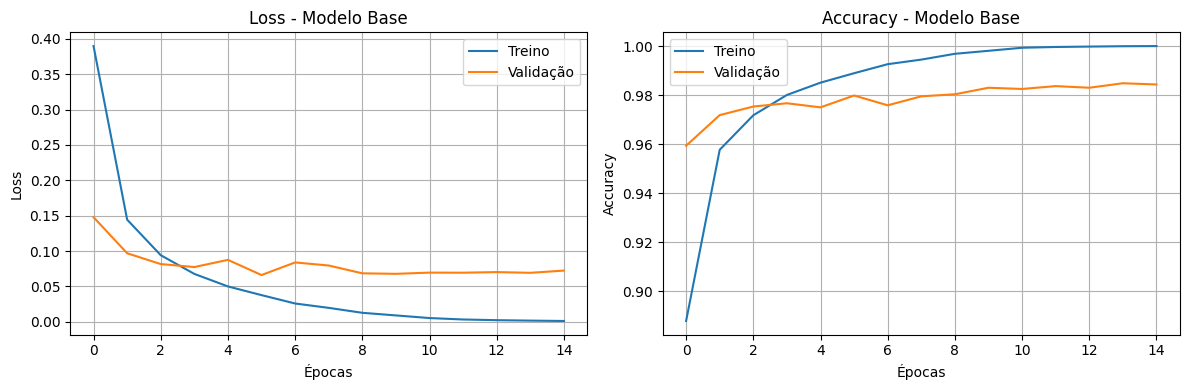

In [7]:
plotar_historico(historico_base, 'Modelo Base')

In [8]:
loss_base, acc_base = model.evaluate(X_test, y_test, verbose=0)

print(f"Acurácia no teste: {acc_base:.4f}")
print(f"Loss no teste: {loss_base:.4f}")

Acurácia no teste: 0.9838
Loss no teste: 0.0658


In [9]:
def criar_modelo_l2():
    backend.clear_session()

    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),

        Dense(1024, activation='relu',
              kernel_regularizer=L2(0.0002)),

        Dense(512, activation='relu',
              kernel_regularizer=L2(0.0002)),

        Dense(256, activation='relu',
              kernel_regularizer=L2(0.0002)),

        Dense(128, activation='relu',
              kernel_regularizer=L2(0.0002)),

        Dense(10, activation='softmax')
    ])

    return model

In [10]:
model_l2 = criar_modelo_l2()

model_l2.compile(
    optimizer=SGD(learning_rate=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

inicio = time.time()

historico_l2 = model_l2.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_split=0.1,
    verbose=1
)

tempo_l2 = time.time() - inicio

print(f"\nTempo de treinamento: {tempo_l2:.2f} segundos")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8870 - loss: 0.8053 - val_accuracy: 0.9595 - val_loss: 0.5509
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9569 - loss: 0.5509 - val_accuracy: 0.9598 - val_loss: 0.5268
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9712 - loss: 0.4926 - val_accuracy: 0.9758 - val_loss: 0.4711
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9788 - loss: 0.4572 - val_accuracy: 0.9695 - val_loss: 0.4822
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9835 - loss: 0.4302 - val_accuracy: 0.9788 - val_loss: 0.4396
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9871 - loss: 0.4085 - val_accuracy: 0.9802 - val_loss: 0.4327
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9910 - loss: 0.3876 - val_accuracy: 0.9802 - val_loss: 0.4212
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9933 - loss: 0.3708 - val_accuracy: 0.

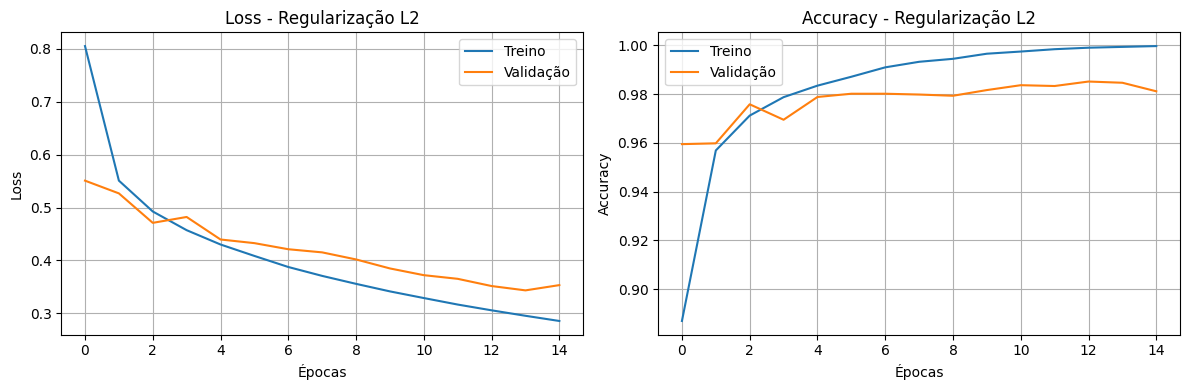

In [11]:
plotar_historico(historico_l2, 'Regularização L2')

In [12]:
loss_l2, acc_l2 = model_l2.evaluate(X_test, y_test, verbose=0)

print(f"Acurácia no teste: {acc_l2:.4f}")
print(f"Loss no teste: {loss_l2:.4f}")

Acurácia no teste: 0.9797
Loss no teste: 0.3486


In [13]:
def criar_modelo_dropout():
    backend.clear_session()

    model = Sequential([
        Input(shape=(28, 28)),
        Flatten(),

        Dropout(0.10),

        Dense(1024, activation='relu'),
        Dropout(0.20),

        Dense(512, activation='relu'),
        Dropout(0.20),

        Dense(256, activation='relu'),
        Dropout(0.40),

        Dense(128, activation='relu'),
        Dropout(0.50),

        Dense(10, activation='softmax')
    ])

    return model

In [14]:
model_dropout = criar_modelo_dropout()

model_dropout.compile(
    optimizer=SGD(learning_rate=0.05),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

inicio = time.time()

historico_dropout = model_dropout.fit(
    X_train,
    y_train,
    batch_size=64,
    epochs=15,
    validation_split=0.1,
    verbose=1
)

tempo_dropout = time.time() - inicio

print(f"\nTempo de treinamento: {tempo_dropout:.2f} segundos")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - accuracy: 0.7760 - loss: 0.6991 - val_accuracy: 0.9495 - val_loss: 0.1694
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9172 - loss: 0.2922 - val_accuracy: 0.9663 - val_loss: 0.1113
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9417 - loss: 0.2104 - val_accuracy: 0.9717 - val_loss: 0.0938
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9519 - loss: 0.1676 - val_accuracy: 0.9743 - val_loss: 0.0797
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9603 - loss: 0.1411 - val_accuracy: 0.9770 - val_loss: 0.0777
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9655 - loss: 0.1233 - val_accuracy: 0.9808 - val_loss: 0.0682
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9679 - loss: 0.1112 - val_accuracy: 0.9818 - val_loss: 0.0678
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9725 - loss: 0.0970 - val_accuracy: 

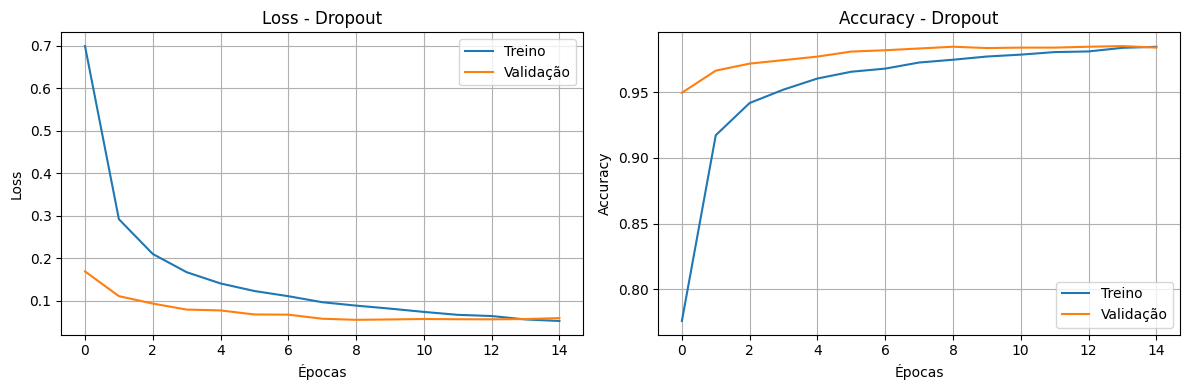

In [15]:
plotar_historico(historico_dropout, 'Dropout')

In [16]:
loss_dropout, acc_dropout = model_dropout.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Acurácia no teste: {acc_dropout:.4f}")
print(f"Loss no teste: {loss_dropout:.4f}")

Acurácia no teste: 0.9825
Loss no teste: 0.0657


In [17]:
resultados = {
    'Modelo Base': acc_base,
    'Regularização L2': acc_l2,
    'Dropout': acc_dropout
}

for nome, resultado in resultados.items():
    print(f"{nome}: {resultado:.4f}")

Modelo Base: 0.9838
Regularização L2: 0.9797
Dropout: 0.9825


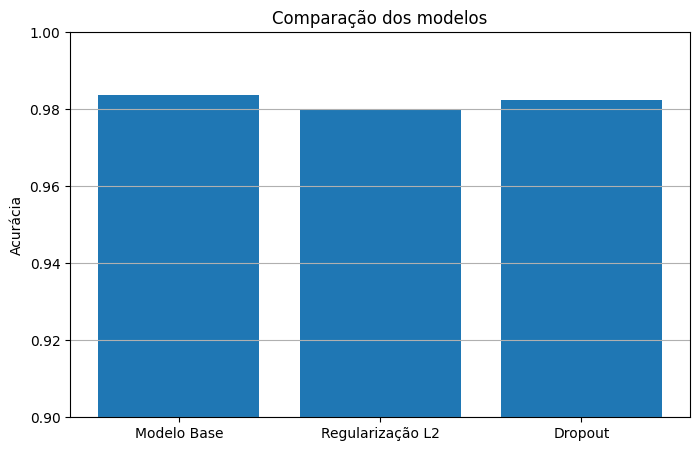

In [18]:
plt.figure(figsize=(8, 5))

plt.bar(resultados.keys(), resultados.values())

plt.ylabel('Acurácia')
plt.title('Comparação dos modelos')
plt.ylim(0.90, 1.00)
plt.grid(axis='y')

plt.show()

In [19]:
batch_sizes = [32, 64, 128]

resultados_batch = []

for batch in batch_sizes:

    model = criar_modelo_dropout()

    model.compile(
        optimizer=SGD(learning_rate=0.05),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    inicio = time.time()

    model.fit(
        X_train,
        y_train,
        batch_size=batch,
        epochs=10,
        validation_split=0.1,
        verbose=0
    )

    tempo = time.time() - inicio

    _, accuracy = model.evaluate(X_test, y_test, verbose=0)

    resultados_batch.append([batch, accuracy, tempo])

    print(
        f"Batch Size: {batch} | "
        f"Acurácia: {accuracy:.4f} | "
        f"Tempo: {tempo:.2f}s"
    )

Batch Size: 32 | Acurácia: 0.9814 | Tempo: 63.71s
Batch Size: 64 | Acurácia: 0.9813 | Tempo: 34.27s
Batch Size: 128 | Acurácia: 0.9775 | Tempo: 24.01s


In [20]:
epocas = [5, 10, 15, 20]

resultados_epocas = []

for epoch in epocas:

    model = criar_modelo_dropout()

    model.compile(
        optimizer=SGD(learning_rate=0.05),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    inicio = time.time()

    model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=epoch,
        validation_split=0.1,
        verbose=0
    )

    tempo = time.time() - inicio

    _, accuracy = model.evaluate(X_test, y_test, verbose=0)

    resultados_epocas.append([epoch, accuracy, tempo])

    print(
        f"Épocas: {epoch} | "
        f"Acurácia: {accuracy:.4f} | "
        f"Tempo: {tempo:.2f}s"
    )

Épocas: 5 | Acurácia: 0.9747 | Tempo: 23.09s
Épocas: 10 | Acurácia: 0.9786 | Tempo: 33.29s
Épocas: 15 | Acurácia: 0.9828 | Tempo: 47.07s
Épocas: 20 | Acurácia: 0.9831 | Tempo: 61.82s


In [21]:
otimizadores = {
    'SGD': SGD(learning_rate=0.05),
    'Adam': Adam(learning_rate=0.001),
    'RMSprop': RMSprop(learning_rate=0.001)
}

resultados_otimizadores = []

for nome, otimizador in otimizadores.items():

    model = criar_modelo_dropout()

    model.compile(
        optimizer=otimizador,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    inicio = time.time()

    model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=10,
        validation_split=0.1,
        verbose=0
    )

    tempo = time.time() - inicio

    _, accuracy = model.evaluate(X_test, y_test, verbose=0)

    resultados_otimizadores.append(
        [nome, accuracy, tempo]
    )

    print(
        f"Otimizador: {nome} | "
        f"Acurácia: {accuracy:.4f} | "
        f"Tempo: {tempo:.2f}s"
    )

Otimizador: SGD | Acurácia: 0.9807 | Tempo: 36.41s
Otimizador: Adam | Acurácia: 0.9802 | Tempo: 39.56s
Otimizador: RMSprop | Acurácia: 0.9755 | Tempo: 37.69s


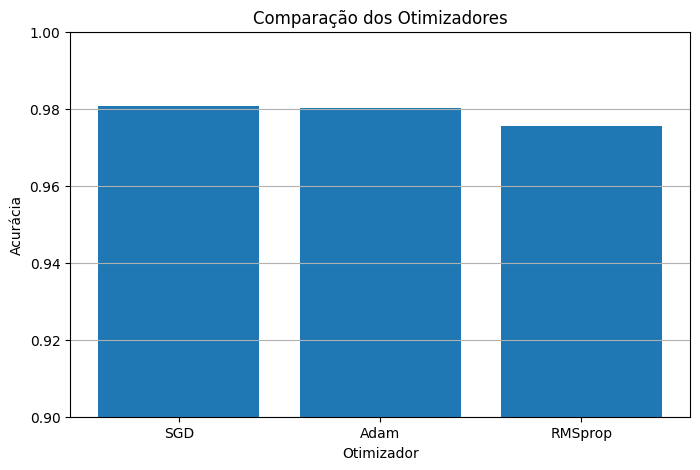

In [22]:
nomes = [resultado[0] for resultado in resultados_otimizadores]
acuracias = [resultado[1] for resultado in resultados_otimizadores]

plt.figure(figsize=(8, 5))

plt.bar(nomes, acuracias)

plt.xlabel('Otimizador')
plt.ylabel('Acurácia')
plt.title('Comparação dos Otimizadores')
plt.ylim(0.90, 1.00)
plt.grid(axis='y')

plt.show()

In [23]:
learning_rates = [0.001, 0.005, 0.01]

resultados_lr = []

for lr in learning_rates:

    model = criar_modelo_dropout()

    model.compile(
        optimizer=SGD(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    inicio = time.time()

    model.fit(
        X_train,
        y_train,
        batch_size=64,
        epochs=10,
        validation_split=0.1,
        verbose=0
    )

    tempo = time.time() - inicio

    _, accuracy = model.evaluate(X_test, y_test, verbose=0)

    resultados_lr.append([lr, accuracy, tempo])

    print(
        f"Learning Rate: {lr} | "
        f"Acurácia: {accuracy:.4f} | "
        f"Tempo: {tempo:.2f}s"
    )

Learning Rate: 0.001 | Acurácia: 0.8810 | Tempo: 35.74s
Learning Rate: 0.005 | Acurácia: 0.9475 | Tempo: 35.29s
Learning Rate: 0.01 | Acurácia: 0.9635 | Tempo: 33.30s


In [24]:
import pandas as pd

df_batch = pd.DataFrame(
    resultados_batch,
    columns=['Batch Size', 'Acurácia', 'Tempo (s)']
)

df_epocas = pd.DataFrame(
    resultados_epocas,
    columns=['Épocas', 'Acurácia', 'Tempo (s)']
)

df_otimizadores = pd.DataFrame(
    resultados_otimizadores,
    columns=['Otimizador', 'Acurácia', 'Tempo (s)']
)

df_lr = pd.DataFrame(
    resultados_lr,
    columns=['Learning Rate', 'Acurácia', 'Tempo (s)']
)

In [25]:
print("RESULTADOS - BATCH SIZE")
display(df_batch)

print("\nRESULTADOS - ÉPOCAS")
display(df_epocas)

print("\nRESULTADOS - OTIMIZADORES")
display(df_otimizadores)

print("\nRESULTADOS - LEARNING RATE")
display(df_lr)

RESULTADOS - BATCH SIZE


,Batch Size,Acurácia,Tempo (s)
0,32,0.9814,63.712519
1,64,0.9813,34.268786
2,128,0.9775,24.014945



RESULTADOS - ÉPOCAS


,Épocas,Acurácia,Tempo (s)
0,5,0.9747,23.086767
1,10,0.9786,33.294074
2,15,0.9828,47.069639
3,20,0.9831,61.819722



RESULTADOS - OTIMIZADORES


,Otimizador,Acurácia,Tempo (s)
0,SGD,0.9807,36.411714
1,Adam,0.9802,39.563851
2,RMSprop,0.9755,37.691309



RESULTADOS - LEARNING RATE


,Learning Rate,Acurácia,Tempo (s)
0,0.001,0.8810,35.738702
1,0.005,0.9475,35.286615
2,0.010,0.9635,33.304283


In [26]:
# Configuração final
batch_final = 64
epocas_final = 15
learning_rate_final = 0.001

modelo_final = criar_modelo_dropout()

modelo_final.compile(
    optimizer=Adam(learning_rate=learning_rate_final),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

inicio = time.time()

historico_final = modelo_final.fit(
    X_train,
    y_train,
    batch_size=batch_final,
    epochs=epocas_final,
    validation_split=0.1,
    verbose=1
)

tempo_final = time.time() - inicio

loss_final, acc_final = modelo_final.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"\nAcurácia final: {acc_final:.4f}")
print(f"Loss final: {loss_final:.4f}")
print(f"Tempo final: {tempo_final:.2f} segundos")

Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.8860 - loss: 0.3848 - val_accuracy: 0.9675 - val_loss: 0.1083
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9549 - loss: 0.1670 - val_accuracy: 0.9753 - val_loss: 0.0887
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9649 - loss: 0.1319 - val_accuracy: 0.9765 - val_loss: 0.0887
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9703 - loss: 0.1098 - val_accuracy: 0.9788 - val_loss: 0.0827
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9739 - loss: 0.1004 - val_accuracy: 0.9820 - val_loss: 0.0665
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9775 - loss: 0.0824 - val_accuracy: 0.9808 - val_loss: 0.0781
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9795 - loss: 0.0752 - val_accuracy: 0.9790 - val_loss: 0.0773
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9808 - loss: 0.0698 - val_accuracy: 0

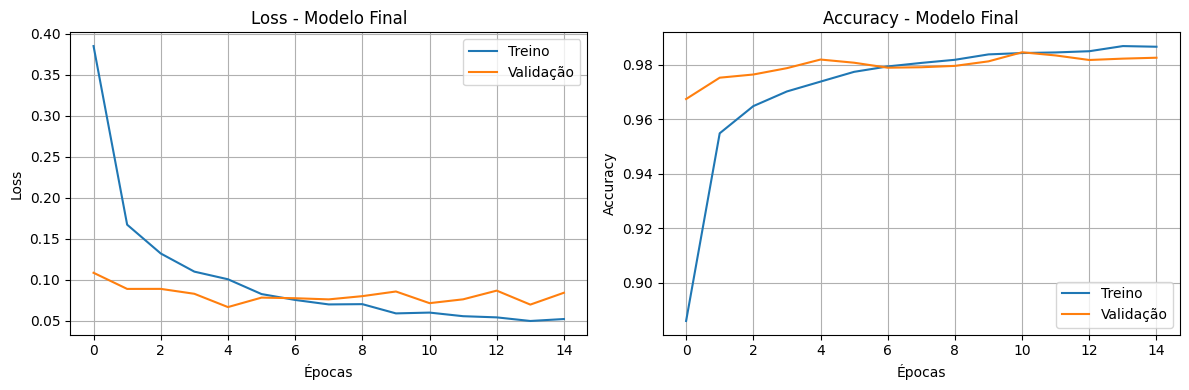

In [27]:
plotar_historico(historico_final, 'Modelo Final')

In [28]:
modelo_final.save('modelo_mnist_part4.keras')

print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


In [30]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
import os

# Criar a pasta models caso ela não exista
caminho = '/content/drive/MyDrive/Colab Notebooks/models'
os.makedirs(caminho, exist_ok=True)

print("Pasta pronta!")

Pasta pronta!


In [34]:
modelo_final.save(
    '/content/drive/MyDrive/Colab Notebooks/models/modelo_mnist_part4.keras'
)

print("Modelo salvo no Google Drive!")

Modelo salvo no Google Drive!


In [35]:
indice = 0

imagem = X_test[indice]

predicao = modelo_final.predict(
    np.expand_dims(imagem, axis=0),
    verbose=0
)

classe_predita = np.argmax(predicao)

print("Classe real:", y_test[indice])
print("Classe predita:", classe_predita)

Classe real: 7
Classe predita: 7


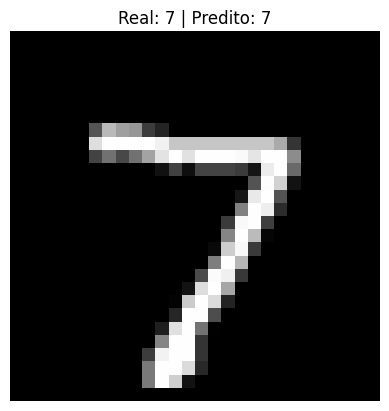

In [36]:
plt.imshow(X_test[indice], cmap='gray')
plt.title(
    f"Real: {y_test[indice]} | Predito: {classe_predita}"
)
plt.axis('off')
plt.show()

## Conclusão

Neste trabalho foram analisadas técnicas para identificar e reduzir o problema de overfitting em redes neurais utilizando o banco de dados MNIST.

Inicialmente foi treinado um modelo base com quatro camadas ocultas. Em seguida, foram testadas técnicas de regularização, como L2 e Dropout. Também foram realizados experimentos modificando hiperparâmetros como número de épocas, batch size, otimizador e learning rate.

Os resultados mostraram que a escolha dos hiperparâmetros influencia diretamente o desempenho da rede neural. A utilização do Dropout também apresentou uma alternativa para reduzir o overfitting e melhorar a capacidade de generalização do modelo.

Por fim, foi selecionada uma configuração para o treinamento do modelo final, que foi avaliada utilizando o conjunto de teste e salva para utilização em trabalhos posteriores.